# Phase 2.2 Experiment 3: Does filtering GTZAN improve the base CNN?

## Research question

Compare the Phase 2.2 CNN trained on the full eligible GTZAN training split with the same CNN trained only on tracks listed in [`filtered_splits/dataset_filtered.txt`](https://github.com/Rani1281/MusicGenreClassification/blob/main/filtered_splits/dataset_filtered.txt). The repository manifest is the filter for exact repetitions, distorted recordings, and suspected mislabels.

## Comparison design

- Keep the reference workflow: 30-second tracks, six 5-second log-mel windows, the same five-block CNN, early stopping, and track-level probability averaging.
- Make one stratified, hash-grouped train/validation/test split from the full corpus first. Both runs use the same curated validation tracks and exactly the same full held-out test tracks.
- The full-data run uses every eligible training track. The filtered run uses only training tracks in the GitHub manifest. The test set is not filtered; manifest membership is recorded so results can be inspected for kept versus removed songs.
- Compare overall accuracy, balanced accuracy, macro-F1, per-genre precision/recall/F1, confusion matrices, and paired track-level outcomes, with a closer look at reggae, rock, and country.

The folder label is still the evaluation target. Since some folder labels may themselves be wrong, a prediction that disagrees with a questionable folder label can count as an error. Manifest membership is a curator signal, not independent proof that a song is mislabeled. Treat small per-genre changes as exploratory.

Run the cells top to bottom. The first run downloads the GTZAN archive (about 1.23 GB) if audio is not already present, fetches the manifest in Colab, and creates reusable features under `artifacts/`.

## 1. Download and prepare GTZAN

This is the data setup from the Phase 2.2 workflow. It downloads the Marsyas GTZAN archive when needed and extracts the 10 genre folders. The known corrupted `jazz.00054.wav` is skipped as in the reference notebook.

In [1]:
import importlib.util
import shutil
import subprocess
import sys
import tarfile
from pathlib import Path, PurePosixPath

if importlib.util.find_spec("huggingface_hub") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"])
from huggingface_hub import hf_hub_download

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    PROJECT_DIR = Path("/content")
else:
    current_and_parent_dirs = [Path.cwd(), *Path.cwd().parents]
    PROJECT_DIR = next(
        (path for path in current_and_parent_dirs if (path / "filtered_splits").is_dir()),
        Path.cwd(),
    )
DATA_DIR = PROJECT_DIR / "data" / "genres_original"
GENRE_FOLDERS = [
    "blues", "classical", "country", "disco", "hiphop",
    "jazz", "metal", "pop", "reggae", "rock",
]

# returns a dictionary of each genre and how many files are stored under its name.
def genre_file_counts(root):
    return {
        genre: len(list((root / genre).glob("*.wav")))
        for genre in GENRE_FOLDERS
    }

# Creates the directory
# parents=True means create the directory if it doesn't exist
# exist_ok=True means reuse the directory if it exists already (don't raise an error)
DATA_DIR.mkdir(parents=True, exist_ok=True)
existing_counts = genre_file_counts(DATA_DIR)

# checks whether all values (counts) inside the genre counts dict are bigger or equal to 90.
# If so, skips the download
if all(count >= 90 for count in existing_counts.values()):
    print(f"GTZAN is already present at {DATA_DIR.resolve()} — skipping download.")
else:
    archive_path = hf_hub_download(
        repo_id="marsyas/gtzan",
        repo_type="dataset",
        filename="data/genres.tar.gz",
        local_dir=str(PROJECT_DIR / "data" / "downloads"),
    )
    print(f"Downloaded archive: {archive_path}")

    extracted_files = 0
    with tarfile.open(archive_path, mode="r:gz") as archive:
        for member in archive.getmembers():
            if not member.isfile():
                continue
            member_path = PurePosixPath(member.name)
            if member_path.is_absolute() or ".." in member_path.parts:
                raise ValueError(f"Unsafe path in GTZAN archive: {member.name}")
            filename = member_path.name
            if not filename.lower().endswith(".wav") or filename.startswith("._"):
                continue
            genres_in_path = [
                part.lower() for part in member_path.parts[:-1]
                if part.lower() in GENRE_FOLDERS
            ]
            if not genres_in_path:
                continue
            genre = genres_in_path[-1]
            if genre == "jazz" and filename == "jazz.00054.wav":
                continue
            destination = DATA_DIR / genre / filename
            destination.parent.mkdir(parents=True, exist_ok=True)
            with archive.extractfile(member) as source, destination.open("wb") as target:
                shutil.copyfileobj(source, target)
            extracted_files += 1

    final_counts = genre_file_counts(DATA_DIR)
    missing_or_incomplete = {genre: count for genre, count in final_counts.items() if count < 90}
    if missing_or_incomplete:
        raise RuntimeError(
            f"GTZAN extraction looks incomplete: {missing_or_incomplete}. "
            "Check the Colab internet connection and rerun this cell."
        )
    print(f"Extracted {extracted_files} usable WAV files into {DATA_DIR.resolve()}")
    print("Files per genre:", final_counts)

print(f"Dataset directory ready: {DATA_DIR.resolve()}")

data/genres.tar.gz: reconstructing file:   0%|          |  0.00B / 1.23GB            

data/genres.tar.gz: downloading bytes:           |  0.00B            

Downloaded archive: /content/data/downloads/data/genres.tar.gz
Extracted 999 usable WAV files into /content/data/genres_original
Files per genre: {'blues': 100, 'classical': 100, 'country': 100, 'disco': 100, 'hiphop': 100, 'jazz': 99, 'metal': 100, 'pop': 100, 'reggae': 100, 'rock': 100}
Dataset directory ready: /content/data/genres_original


## 2. Imports, settings, and reproducibility

In [2]:
import hashlib
import math
import random
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torch.nn as nn
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, Dataset
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Deterministic kernels can make repeated runs easier to compare.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Audio and feature settings
PROJECT_DIR = PROJECT_DIR  # detected in the dataset setup cell above
DATA_DIR = PROJECT_DIR / "data" / "genres_original"
SAMPLE_RATE = 22_050
TRACK_SECONDS = 30
SEGMENT_SECONDS = 5
N_MELS = 128
N_FFT = 2_048
HOP_LENGTH = 512
DB_RANGE = 80.0

# Training settings
BATCH_SIZE = 32
EPOCHS = 30
PATIENCE = 8
LEARNING_RATE = 1e-3

ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
CHECKPOINT_DIR = ARTIFACTS_DIR / "phase_2_2_experiment_3"

print(f"PyTorch: {torch.__version__}")
print(f"Device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Dataset folder: {DATA_DIR.resolve()}")

PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4
Dataset folder: /content/data/genres_original


## 3. Index the audio and identify exact copies

In [3]:
# A few common extraction layouts are checked before asking you to edit DATA_DIR.
if not DATA_DIR.exists():
    alternatives = [
        Path("genres_original"),
        Path("Data/genres_original"),
        Path("data/Data/genres_original"),
    ]
    DATA_DIR = next((path for path in alternatives if path.exists()), DATA_DIR)

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Could not find the GTZAN genre folders at {DATA_DIR.resolve()}. "
        "Extract the dataset and set DATA_DIR to the folder that directly contains "
        "the ten genre folders."
    )

audio_extensions = {".wav", ".au", ".mp3", ".flac", ".ogg"}
genre_dirs = sorted(path for path in DATA_DIR.iterdir() if path.is_dir())
CLASS_NAMES = [path.name for path in genre_dirs]
if len(CLASS_NAMES) != 10:
    raise ValueError(
        f"Expected 10 genre folders, found {len(CLASS_NAMES)}: {CLASS_NAMES}. "
        "Check that DATA_DIR points to the folder containing the genre folders."
    )

class_to_id = {name: index for index, name in enumerate(CLASS_NAMES)}

def sha256_file(path, block_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as audio_file:
        for block in iter(lambda: audio_file.read(block_size), b""):
            digest.update(block)
    return digest.hexdigest()

records = []
for genre_dir in genre_dirs:
    for audio_path in sorted(genre_dir.iterdir()):
        if audio_path.is_file() and audio_path.suffix.lower() in audio_extensions:
            try:
                audio_info = sf.info(str(audio_path))
                file_hash = sha256_file(audio_path)
            except (OSError, RuntimeError, ValueError) as error:
                print(f"Skipping unreadable audio file {audio_path}: {error}")
                continue
            records.append(
                {
                    "path": audio_path.resolve(),
                    "track_name": audio_path.name,
                    "relative_path": PurePosixPath(genre_dir.name, audio_path.name).as_posix(),
                    "genre": genre_dir.name,
                    "label_id": class_to_id[genre_dir.name],
                    "duration_seconds": audio_info.duration,
                    "sha256": file_hash,
                }
            )

tracks = pd.DataFrame(records)
if tracks.empty:
    raise ValueError(
        f"No supported audio files found directly inside the genre folders in {DATA_DIR}."
    )

print(f"Found {len(tracks)} audio files across {tracks['genre'].nunique()} genres.")
display(tracks.head())

Found 999 audio files across 10 genres.


,path,track_name,relative_path,genre,label_id,duration_seconds,sha256
0,/content/data/genres_original/blues/blues.0000...,blues.00000.wav,blues/blues.00000.wav,blues,0,30.013333,728e445a61ebb2ab9cefe779a9af5c44cff39f20308a0a...
1,/content/data/genres_original/blues/blues.0000...,blues.00001.wav,blues/blues.00001.wav,blues,0,30.013333,be8530fd9cfcd43182a4356b7da0fbc8a3e2a5c3532e30...
2,/content/data/genres_original/blues/blues.0000...,blues.00002.wav,blues/blues.00002.wav,blues,0,30.013333,2ee18ebafb37a3404397720a1d1342ffd0e19565224fe3...
3,/content/data/genres_original/blues/blues.0000...,blues.00003.wav,blues/blues.00003.wav,blues,0,30.013333,c115b31b147cce0da7b0e52173dc61266d8cabfa060bb7...
4,/content/data/genres_original/blues/blues.0000...,blues.00004.wav,blues/blues.00004.wav,blues,0,30.013333,06bc76188dbadeb53aeae58c11764ef4727b539d166555...


## 4. Inspect class balance, durations, and conflicting exact copies

In [4]:
print("Files per genre:")
display(tracks.groupby("genre").size().rename("file_count").to_frame())

print(
    "\nDuration summary (seconds): "
    f"min={tracks['duration_seconds'].min():.2f}, "
    f"median={tracks['duration_seconds'].median():.2f}, "
    f"max={tracks['duration_seconds'].max():.2f}"
)

all_indexed_manifest_paths = {
    str(path).replace("\\", "/").removeprefix("./").casefold()
    for path in tracks["relative_path"]
}

duplicate_mask = tracks.duplicated("sha256", keep=False)
duplicate_files = tracks.loc[duplicate_mask].sort_values(["sha256", "genre"])
conflicting_hashes = (
    tracks.groupby("sha256")["genre"].nunique().loc[lambda counts: counts > 1].index
)
print(f"\nFiles that are exact copies of another file: {int(duplicate_mask.sum())}")
print(f"Exact-content groups assigned conflicting genre labels: {len(conflicting_hashes)}")

if len(conflicting_hashes):
    print("Conflicting exact copies (excluded from this run):")
    display(duplicate_files[duplicate_files["sha256"].isin(conflicting_hashes)][
        ["track_name", "genre", "sha256"]
    ])

# A copy with conflicting labels has no unambiguous supervised target.
tracks = tracks.loc[~tracks["sha256"].isin(conflicting_hashes)].reset_index(drop=True)

print(f"\nFiles kept for modeling: {len(tracks)}")
display(tracks.groupby("genre").size().rename("usable_file_count").to_frame())

Files per genre:


,file_count
genre,
blues,100
classical,100
country,100
disco,100
hiphop,100
jazz,99
metal,100
pop,100
reggae,100



Duration summary (seconds): min=29.93, median=30.01, max=30.65

Files that are exact copies of another file: 28
Exact-content groups assigned conflicting genre labels: 1
Conflicting exact copies (excluded from this run):


,track_name,genre,sha256
657,metal.00058.wav,metal,56e2b93b263a1f29ced0090d615d40755e9dc19b806623...
915,rock.00016.wav,rock,56e2b93b263a1f29ced0090d615d40755e9dc19b806623...



Files kept for modeling: 997


,usable_file_count
genre,
blues,100
classical,100
country,100
disco,100
hiphop,100
jazz,99
metal,99
pop,100
reggae,100


## 5. Load the filtered manifest from the project GitHub repository

In Colab this reads `filtered_splits/dataset_filtered.txt` from the repository's `main` branch. In a local checkout it uses the checked-out copy of that same file. Audio paths in the manifest are matched as `genre/filename.wav`.

In [5]:
from urllib.request import urlopen

FILTERED_MANIFEST_URL = (
    "https://raw.githubusercontent.com/Rani1281/MusicGenreClassification/"
    "main/filtered_splits/dataset_filtered.txt"
)
LOCAL_MANIFEST_PATH = PROJECT_DIR / "filtered_splits" / "dataset_filtered.txt"

if not IN_COLAB and LOCAL_MANIFEST_PATH.is_file():
    manifest_text = LOCAL_MANIFEST_PATH.read_text(encoding="utf-8")
    manifest_source = str(LOCAL_MANIFEST_PATH.resolve())
else:
    with urlopen(FILTERED_MANIFEST_URL, timeout=60) as response:
        manifest_text = response.read().decode("utf-8-sig")
    manifest_source = FILTERED_MANIFEST_URL


def normalize_manifest_path(path):
    return str(path).strip().replace("\\", "/").removeprefix("./").casefold()


filtered_manifest_paths = {
    normalize_manifest_path(line)
    for line in manifest_text.splitlines()
    if line.strip()
}
if not filtered_manifest_paths:
    raise ValueError("The filtered GTZAN manifest is empty.")

tracks["manifest_path"] = tracks["relative_path"].map(normalize_manifest_path)
tracks["in_filtered_manifest"] = tracks["manifest_path"].isin(filtered_manifest_paths)
manifest_paths_without_audio = sorted(
    filtered_manifest_paths - all_indexed_manifest_paths
)

print(f"Filtered manifest source: {manifest_source}")
print(f"Manifest entries: {len(filtered_manifest_paths)}")
print(f"Manifest entries not found in the original audio index: {len(manifest_paths_without_audio)}")
if manifest_paths_without_audio:
    display(pd.DataFrame({"manifest_path_not_found": manifest_paths_without_audio}).head(20))
if not tracks["in_filtered_manifest"].any():
    raise ValueError(
        "None of the filtered manifest paths matched the indexed audio. "
        "Check DATA_DIR and the GitHub manifest path format."
    )

manifest_summary = (
    tracks.groupby("genre")["in_filtered_manifest"]
    .agg(filtered_count="sum", eligible_count="size")
)
manifest_summary["removed_count"] = (
    manifest_summary["eligible_count"] - manifest_summary["filtered_count"]
)
manifest_summary["filtered_percent"] = (
    100 * manifest_summary["filtered_count"] / manifest_summary["eligible_count"]
)
display(manifest_summary.round(1))
print(
    f"Matched tracks: {int(tracks['in_filtered_manifest'].sum())}/{len(tracks)} "
    "after excluding exact-content groups with conflicting folder labels)."
)


Filtered manifest source: https://raw.githubusercontent.com/Rani1281/MusicGenreClassification/main/filtered_splits/dataset_filtered.txt
Manifest entries: 895
Manifest entries not found in the original audio index: 1


,manifest_path_not_found
0,jazz/jazz.00054.wav


,filtered_count,eligible_count,removed_count,filtered_percent
genre,,,,
blues,100,100,0,100.0
classical,99,100,1,99.0
country,97,100,3,97.0
disco,92,100,8,92.0
hiphop,89,100,11,89.0
jazz,84,99,15,84.8
metal,80,99,19,80.8
pop,82,100,18,82.0
reggae,85,100,15,85.0


Matched tracks: 893/997 after excluding exact-content groups with conflicting folder labels).


## 6. Create one shared, leakage-aware split

The split follows the reference approach: stratify at the track level and group byte-identical files by SHA-256 before creating windows. One fold from five is held out for test; one fold from nine of the remaining tracks is validation. The full-data model trains on all training tracks. The filtered model trains on the manifest subset. Both select checkpoints on the same manifest-included validation tracks and are evaluated on the same unfiltered test split.

In [6]:
if tracks["genre"].nunique() != 10 or tracks.groupby("genre").size().min() < 10:
    raise ValueError(
        "The indexed GTZAN data needs at least 10 tracks in each of the 10 genres "
        "for this stratified split."
    )

all_indices = np.arange(len(tracks))
labels = tracks["label_id"].to_numpy()
groups = tracks["sha256"].to_numpy()

# Make one fixed split from the full eligible corpus before applying the manifest.
# Exact-content copies remain grouped, so none can cross train/validation/test.
outer_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_validation_indices, test_indices = next(
    outer_splitter.split(np.zeros(len(tracks)), labels, groups)
)

remaining_labels = labels[train_validation_indices]
remaining_groups = groups[train_validation_indices]
inner_splitter = StratifiedGroupKFold(n_splits=9, shuffle=True, random_state=SEED + 1)
train_relative, validation_relative = next(
    inner_splitter.split(
        np.zeros(len(train_validation_indices)),
        remaining_labels,
        remaining_groups,
    )
)
train_indices = train_validation_indices[train_relative]
validation_indices = train_validation_indices[validation_relative]

train_tracks_all = tracks.iloc[train_indices].reset_index(drop=True)
validation_tracks_all = tracks.iloc[validation_indices].reset_index(drop=True)
test_tracks = tracks.iloc[test_indices].reset_index(drop=True)

# Both models use exactly the same curated validation tracks for checkpoint
# selection. The test set remains the same full held-out set for both models.
train_tracks_filtered = train_tracks_all.loc[
    train_tracks_all["in_filtered_manifest"]
].reset_index(drop=True)
validation_tracks = validation_tracks_all.loc[
    validation_tracks_all["in_filtered_manifest"]
].reset_index(drop=True)

if train_tracks_filtered.empty or validation_tracks.empty:
    raise ValueError("The filtered manifest left no training or validation tracks.")
if validation_tracks.groupby("genre").size().reindex(CLASS_NAMES, fill_value=0).min() < 1:
    raise ValueError(
        "The common filtered validation subset needs at least one track from every genre."
    )
if train_tracks_filtered.groupby("genre").size().reindex(CLASS_NAMES, fill_value=0).min() < 5:
    raise ValueError(
        "The filtered training subset needs at least five tracks from every genre."
    )

tracks["split"] = "test"
tracks.loc[train_indices, "split"] = "train"
tracks.loc[validation_indices, "split"] = "validation"

split_summary = pd.DataFrame(
    {
        "full_training": train_tracks_all.groupby("genre").size(),
        "filtered_training": train_tracks_filtered.groupby("genre").size(),
        "shared_validation": validation_tracks.groupby("genre").size(),
        "shared_test": test_tracks.groupby("genre").size(),
    }
).reindex(CLASS_NAMES).fillna(0).astype(int)
display(split_summary)
print(
    f"Full training: {len(train_tracks_all)} tracks | "
    f"filtered training: {len(train_tracks_filtered)} tracks | "
    f"shared validation: {len(validation_tracks)} tracks | "
    f"shared test: {len(test_tracks)} tracks"
)

split_count_per_hash = tracks.groupby("sha256")["split"].nunique()
assert split_count_per_hash.max() == 1, "An exact-content group crossed a split."


,full_training,filtered_training,shared_validation,shared_test
genre,,,,
blues,75,75,6,19
classical,67,66,11,22
country,71,69,9,20
disco,69,64,8,23
hiphop,79,69,6,15
jazz,64,54,10,25
metal,65,53,10,22
pop,78,62,7,14
reggae,74,65,7,17


Full training: 711 tracks | filtered training: 639 tracks | shared validation: 82 tracks | shared test: 198 tracks


## 7. Convert tracks to cached log-mel spectrograms

In [7]:
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_SAMPLES = SAMPLE_RATE * TRACK_SECONDS
EXPECTED_FRAMES = 1 + EXPECTED_SAMPLES // HOP_LENGTH
NUM_SEGMENTS = math.ceil(TRACK_SECONDS / SEGMENT_SECONDS)
FRAMES_PER_SEGMENT = math.ceil(EXPECTED_FRAMES / NUM_SEGMENTS)

FEATURE_CACHE_DIR = (
    ARTIFACTS_DIR
    / "gtzan_log_mel"
    / f"sr{SAMPLE_RATE}_mels{N_MELS}_fft{N_FFT}_hop{HOP_LENGTH}_sec{TRACK_SECONDS}_db{int(DB_RANGE)}"
)
FEATURE_CACHE_DIR.mkdir(parents=True, exist_ok=True)

def feature_path_for_hash(file_hash):
    return FEATURE_CACHE_DIR / file_hash[:2] / f"{file_hash}.npy"

def extract_log_mel(audio_path):
    audio, _ = librosa.load(
        str(audio_path),
        sr=SAMPLE_RATE,
        mono=True,
        duration=TRACK_SECONDS,
    )
    if len(audio) < EXPECTED_SAMPLES:
        audio = np.pad(audio, (0, EXPECTED_SAMPLES - len(audio)))
    else:
        audio = audio[:EXPECTED_SAMPLES]

    power_mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SAMPLE_RATE,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        power=2.0,
    )
    decibels = librosa.power_to_db(power_mel, ref=np.max, top_db=DB_RANGE)
    scaled = np.clip((decibels + DB_RANGE) / DB_RANGE, 0.0, 1.0).astype(np.float32)

    # Keep a predictable number of frames even if an audio backend differs by one frame.
    if scaled.shape[1] < EXPECTED_FRAMES:
        scaled = np.pad(scaled, ((0, 0), (0, EXPECTED_FRAMES - scaled.shape[1])))
    else:
        scaled = scaled[:, :EXPECTED_FRAMES]
    return scaled

unique_tracks = tracks.drop_duplicates("sha256")
for position, row in enumerate(unique_tracks.itertuples(index=False), start=1):
    cache_path = feature_path_for_hash(row.sha256)
    if not cache_path.exists():
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        np.save(cache_path, extract_log_mel(row.path))
    if position % 100 == 0 or position == len(unique_tracks):
        print(f"Prepared features for {position}/{len(unique_tracks)} unique tracks")

example_mel = np.load(feature_path_for_hash(unique_tracks.iloc[0]["sha256"]))
print(f"Feature cache: {FEATURE_CACHE_DIR.resolve()}")
print(f"One track feature shape: {example_mel.shape} (mel bands × time frames)")

Prepared features for 100/984 unique tracks
Prepared features for 200/984 unique tracks
Prepared features for 300/984 unique tracks
Prepared features for 400/984 unique tracks
Prepared features for 500/984 unique tracks
Prepared features for 600/984 unique tracks
Prepared features for 700/984 unique tracks
Prepared features for 800/984 unique tracks
Prepared features for 900/984 unique tracks
Prepared features for 984/984 unique tracks
Feature cache: /content/artifacts/gtzan_log_mel/sr22050_mels128_fft2048_hop512_sec30_db80
One track feature shape: (128, 1292) (mel bands × time frames)


## 8. Build track/window datasets and shared loaders

In [8]:
class MelWindowDataset(Dataset):
    def __init__(self, track_table):
        self.track_rows = track_table.to_dict(orient="records")
        self.examples = [
            (track_index, segment_index)
            for track_index, row in enumerate(self.track_rows)
            for segment_index in range(NUM_SEGMENTS)
        ]

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, item_index):
        track_index, segment_index = self.examples[item_index]
        row = self.track_rows[track_index]
        mel = np.load(feature_path_for_hash(row["sha256"]), mmap_mode="r")

        start = segment_index * FRAMES_PER_SEGMENT
        window = np.array(
            mel[:, start : start + FRAMES_PER_SEGMENT],
            dtype=np.float32,
            copy=True,
        )
        if window.shape[1] < FRAMES_PER_SEGMENT:
            window = np.pad(
                window,
                ((0, 0), (0, FRAMES_PER_SEGMENT - window.shape[1])),
            )

        features = torch.from_numpy(window[None, :, :])
        label = torch.tensor(row["label_id"], dtype=torch.long)
        source_track = torch.tensor(track_index, dtype=torch.long)
        return features, label, source_track


full_train_dataset = MelWindowDataset(train_tracks_all)
filtered_train_dataset = MelWindowDataset(train_tracks_filtered)
validation_dataset = MelWindowDataset(validation_tracks)
test_dataset = MelWindowDataset(test_tracks)

validation_loader = DataLoader(
    validation_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)


def make_train_loader(dataset):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=generator,
    )


full_train_loader = make_train_loader(full_train_dataset)
filtered_train_loader = make_train_loader(filtered_train_dataset)
print(f"Full model training windows: {len(full_train_dataset)}")
print(f"Filtered model training windows: {len(filtered_train_dataset)}")
print(f"Shared validation windows: {len(validation_dataset)}")
print(f"Shared test windows: {len(test_dataset)}")


Full model training windows: 4266
Filtered model training windows: 3834
Shared validation windows: 492
Shared test windows: 1188


## 9. Define the Phase 2.2 CNN

In [9]:
class SmallAudioCNN(nn.Module):
    def __init__(self, number_of_classes):
        super().__init__()
        self.filters = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(p=0.30),
            nn.Linear(256, number_of_classes),
        )

    def forward(self, inputs):
        return self.classifier(self.filters(inputs))

## 10. Aggregate window probabilities to track predictions

In [10]:
@torch.inference_mode()
def collect_predictions(model, data_loader, dataset):
    model.eval()
    all_probabilities = []
    all_window_labels = []
    all_track_indices = []

    for features, labels, track_indices in data_loader:
        logits = model(features.to(DEVICE))
        probabilities = torch.softmax(logits, dim=1).cpu().numpy()
        all_probabilities.append(probabilities)
        all_window_labels.append(labels.numpy())
        all_track_indices.append(track_indices.numpy())

    window_probabilities = np.concatenate(all_probabilities)
    window_true = np.concatenate(all_window_labels)
    window_track_indices = np.concatenate(all_track_indices)

    track_probabilities = np.zeros(
        (len(dataset.track_rows), len(CLASS_NAMES)),
        dtype=np.float64,
    )
    window_counts = np.zeros(len(dataset.track_rows), dtype=np.int64)
    np.add.at(track_probabilities, window_track_indices, window_probabilities)
    np.add.at(window_counts, window_track_indices, 1)
    track_probabilities /= window_counts[:, None]

    track_true = np.asarray(
        [row["label_id"] for row in dataset.track_rows],
        dtype=np.int64,
    )
    track_predicted = track_probabilities.argmax(axis=1)

    return {
        "window_probabilities": window_probabilities,
        "window_true": window_true,
        "window_predicted": window_probabilities.argmax(axis=1),
        "window_track_indices": window_track_indices,
        "track_probabilities": track_probabilities,
        "track_true": track_true,
        "track_predicted": track_predicted,
    }

## 11. Train both models with matched initialization and early stopping

The model architecture, optimizer, learning rate, scheduler, epoch limit, patience, and checkpoint rule match the Phase 2.2 base workflow. Each run starts from the same random seed. The validation subset and its evaluation order are shared, so differences on the test set come from the training examples seen by each run (subject to normal training variance).

In [11]:
def reset_random_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def train_model(run_name, train_loader, validation_loader, validation_dataset):
    """Train the reference CNN and select its checkpoint on shared validation tracks."""
    reset_random_seeds(SEED)
    model = SmallAudioCNN(number_of_classes=len(CLASS_NAMES)).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=2
    )

    history = []
    best_score = (-1.0, -1.0)
    best_epoch = 0
    epochs_without_improvement = 0
    best_state = None

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0.0
        correct_windows = 0
        seen_windows = 0

        for features, labels_batch, _ in train_loader:
            features = features.to(DEVICE)
            labels_batch = labels_batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(features)
            loss = criterion(logits, labels_batch)
            loss.backward()
            optimizer.step()

            batch_size = labels_batch.size(0)
            total_loss += loss.item() * batch_size
            correct_windows += (logits.argmax(dim=1) == labels_batch).sum().item()
            seen_windows += batch_size

        validation_result = collect_predictions(
            model, validation_loader, validation_dataset
        )
        validation_accuracy = accuracy_score(
            validation_result["track_true"], validation_result["track_predicted"]
        )
        validation_macro_f1 = f1_score(
            validation_result["track_true"],
            validation_result["track_predicted"],
            average="macro",
            zero_division=0,
        )
        scheduler.step(validation_accuracy)

        epoch_record = {
            "epoch": epoch,
            "train_loss": total_loss / seen_windows,
            "train_window_accuracy": correct_windows / seen_windows,
            "validation_track_accuracy": validation_accuracy,
            "validation_track_macro_f1": validation_macro_f1,
            "learning_rate": optimizer.param_groups[0]["lr"],
        }
        history.append(epoch_record)

        score = (validation_accuracy, validation_macro_f1)
        if score > best_score:
            best_score = score
            best_epoch = epoch
            epochs_without_improvement = 0
            best_state = {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            }
        else:
            epochs_without_improvement += 1

        print(
            f"{run_name} | Epoch {epoch:02d}/{EPOCHS} | "
            f"loss {epoch_record['train_loss']:.4f} | "
            f"train window acc {epoch_record['train_window_accuracy']:.3f} | "
            f"validation track acc {validation_accuracy:.3f} | "
            f"validation macro-F1 {validation_macro_f1:.3f} | "
            f"lr {epoch_record['learning_rate']:.2e}"
        )

        if epochs_without_improvement >= PATIENCE:
            print(f"{run_name}: early stopping after {PATIENCE} epochs without improvement.")
            break

    if best_state is None:
        raise RuntimeError(f"{run_name} training did not produce a checkpoint.")

    model.load_state_dict(best_state)
    model.eval()
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    checkpoint_path = CHECKPOINT_DIR / f"{run_name.lower().replace(' ', '_')}.pt"
    torch.save(
        {
            "model_state_dict": best_state,
            "class_names": CLASS_NAMES,
            "best_epoch": best_epoch,
            "sample_rate": SAMPLE_RATE,
            "track_seconds": TRACK_SECONDS,
            "segment_seconds": SEGMENT_SECONDS,
            "n_mels": N_MELS,
            "n_fft": N_FFT,
            "hop_length": HOP_LENGTH,
            "seed": SEED,
        },
        checkpoint_path,
    )
    print(f"{run_name}: best validation checkpoint at epoch {best_epoch}; saved to {checkpoint_path}")
    return model, pd.DataFrame(history), best_epoch


In [12]:
full_model, full_history, full_best_epoch = train_model(
    "Full GTZAN", full_train_loader, validation_loader, validation_dataset
)

filtered_model, filtered_history, filtered_best_epoch = train_model(
    "Filtered GTZAN", filtered_train_loader, validation_loader, validation_dataset
)

print(f"Full GTZAN best epoch: {full_best_epoch}")
print(f"Filtered GTZAN best epoch: {filtered_best_epoch}")


Full GTZAN | Epoch 01/30 | loss 1.3646 | train window acc 0.509 | validation track acc 0.451 | validation macro-F1 0.427 | lr 1.00e-03
Full GTZAN | Epoch 02/30 | loss 0.9390 | train window acc 0.685 | validation track acc 0.598 | validation macro-F1 0.536 | lr 1.00e-03
Full GTZAN | Epoch 03/30 | loss 0.7656 | train window acc 0.739 | validation track acc 0.683 | validation macro-F1 0.644 | lr 1.00e-03
Full GTZAN | Epoch 04/30 | loss 0.5944 | train window acc 0.798 | validation track acc 0.695 | validation macro-F1 0.672 | lr 1.00e-03
Full GTZAN | Epoch 05/30 | loss 0.5109 | train window acc 0.827 | validation track acc 0.402 | validation macro-F1 0.358 | lr 1.00e-03
Full GTZAN | Epoch 06/30 | loss 0.4545 | train window acc 0.849 | validation track acc 0.537 | validation macro-F1 0.472 | lr 1.00e-03
Full GTZAN | Epoch 07/30 | loss 0.3754 | train window acc 0.878 | validation track acc 0.415 | validation macro-F1 0.347 | lr 5.00e-04
Full GTZAN | Epoch 08/30 | loss 0.2548 | train window a

## 12. Compare learning curves

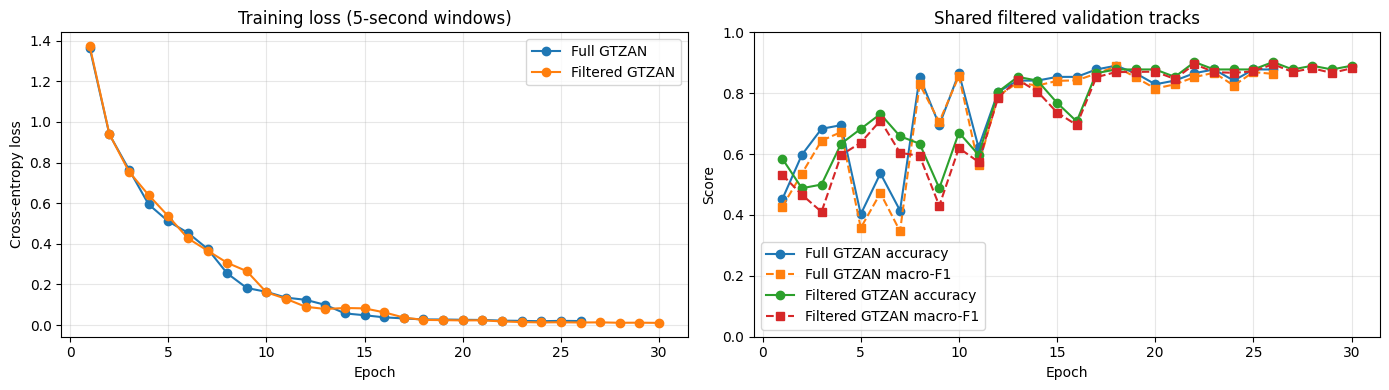

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for run_name, history_table in (
    ("Full GTZAN", full_history),
    ("Filtered GTZAN", filtered_history),
):
    axes[0].plot(
        history_table["epoch"], history_table["train_loss"], marker="o", label=run_name
    )
    axes[1].plot(
        history_table["epoch"],
        history_table["validation_track_accuracy"],
        marker="o",
        label=f"{run_name} accuracy",
    )
    axes[1].plot(
        history_table["epoch"],
        history_table["validation_track_macro_f1"],
        marker="s",
        linestyle="--",
        label=f"{run_name} macro-F1",
    )

axes[0].set_title("Training loss (5-second windows)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].grid(alpha=0.3)
axes[0].legend()
axes[1].set_title("Shared filtered validation tracks")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()


## 13. Compare held-out metrics and confusion matrices

All primary results below use one prediction per full held-out track. The test split is identical for both training runs and includes tracks omitted from the filtered manifest.

Held-out TEST metrics (same tracks for both models)


,accuracy,balanced_accuracy,macro_f1,change_filtered_minus_full
Full GTZAN,0.848,0.845,0.847,NaN
Filtered GTZAN,0.879,0.877,0.874,NaN


,full_precision,filtered_precision,full_recall,filtered_recall,full_f1,filtered_f1,test_support,recall_change,f1_change
blues,0.857,0.895,0.947,0.895,0.900,0.895,19.0,-0.053,-0.005
classical,0.957,0.957,1.000,1.000,0.978,0.978,22.0,0.000,0.000
country,0.750,0.720,0.750,0.900,0.750,0.800,20.0,0.150,0.050
disco,0.870,0.864,0.870,0.826,0.870,0.844,23.0,-0.043,-0.025
hiphop,0.737,0.737,0.933,0.933,0.824,0.824,15.0,0.000,0.000
jazz,0.955,0.960,0.840,0.960,0.894,0.960,25.0,0.120,0.066
metal,0.955,0.957,0.955,1.000,0.955,0.978,22.0,0.045,0.023
pop,1.000,0.929,0.857,0.929,0.923,0.929,14.0,0.071,0.005
reggae,1.000,1.000,0.588,0.706,0.741,0.828,17.0,0.118,0.087
rock,0.577,0.812,0.714,0.619,0.638,0.703,21.0,-0.095,0.064


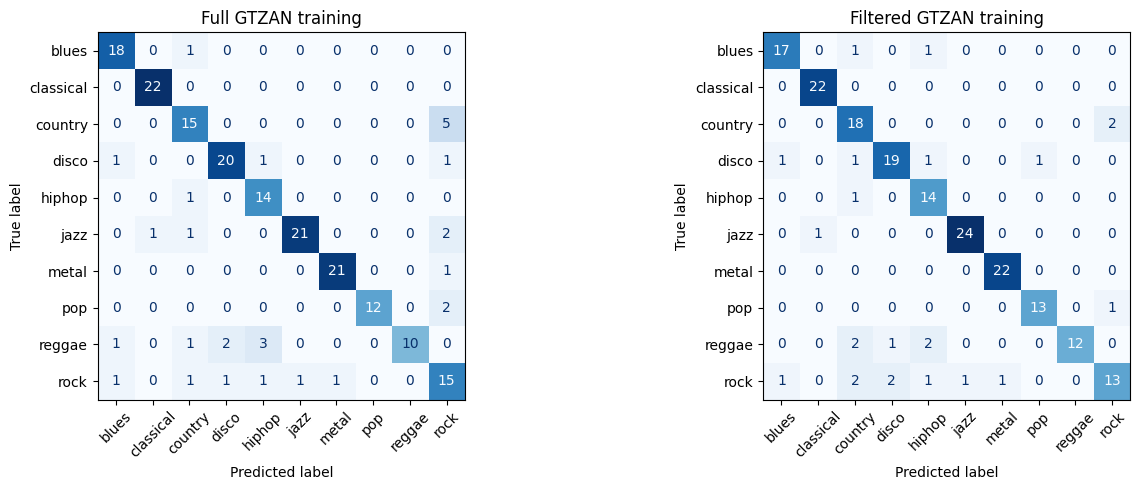

In [14]:
full_test_result = collect_predictions(full_model, test_loader, test_dataset)
filtered_test_result = collect_predictions(filtered_model, test_loader, test_dataset)


def summarize_metrics(result):
    return {
        "accuracy": accuracy_score(result["track_true"], result["track_predicted"]),
        "balanced_accuracy": balanced_accuracy_score(
            result["track_true"], result["track_predicted"]
        ),
        "macro_f1": f1_score(
            result["track_true"],
            result["track_predicted"],
            average="macro",
            zero_division=0,
        ),
    }


metric_comparison = pd.DataFrame(
    {
        "Full GTZAN": summarize_metrics(full_test_result),
        "Filtered GTZAN": summarize_metrics(filtered_test_result),
    }
).T
metric_comparison["change_filtered_minus_full"] = (
    metric_comparison.loc["Filtered GTZAN"] - metric_comparison.loc["Full GTZAN"]
)
print("Held-out TEST metrics (same tracks for both models)")
display(metric_comparison.round(3))

full_report = classification_report(
    full_test_result["track_true"],
    full_test_result["track_predicted"],
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
filtered_report = classification_report(
    filtered_test_result["track_true"],
    filtered_test_result["track_predicted"],
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

class_comparison = pd.DataFrame(
    {
        genre: {
            "full_precision": full_report[genre]["precision"],
            "filtered_precision": filtered_report[genre]["precision"],
            "full_recall": full_report[genre]["recall"],
            "filtered_recall": filtered_report[genre]["recall"],
            "full_f1": full_report[genre]["f1-score"],
            "filtered_f1": filtered_report[genre]["f1-score"],
            "test_support": full_report[genre]["support"],
        }
        for genre in CLASS_NAMES
    }
).T
class_comparison["recall_change"] = (
    class_comparison["filtered_recall"] - class_comparison["full_recall"]
)
class_comparison["f1_change"] = class_comparison["filtered_f1"] - class_comparison["full_f1"]
display(class_comparison.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, result, title in (
    (axes[0], full_test_result, "Full GTZAN training"),
    (axes[1], filtered_test_result, "Filtered GTZAN training"),
):
    ConfusionMatrixDisplay.from_predictions(
        result["track_true"],
        result["track_predicted"],
        labels=np.arange(len(CLASS_NAMES)),
        display_labels=CLASS_NAMES,
        cmap="Blues",
        xticks_rotation=45,
        values_format="d",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()


## 14. Inspect whether filtering changes errors in reggae, rock, and

1.   List item

1.   List item

1.   List item

1.   List item

1.   List item

1.   List item

1.   List item
2.   List item


2.   List item


2.   List item


2.   List item


2.   List item


2.   List item


2.   List item

country

The first table checks whether manifest-removed held-out tracks are harder for either model. The focused tables compare per-genre recall and paired correct/incorrect outcomes on the same tracks. Look at the individual examples alongside the aggregate counts.

In [15]:
test_predictions = pd.DataFrame(
    {
        "track": [row["track_name"] for row in test_dataset.track_rows],
        "true_genre": [CLASS_NAMES[int(x)] for x in full_test_result["track_true"]],
        "in_filtered_manifest": [
            bool(row["in_filtered_manifest"]) for row in test_dataset.track_rows
        ],
        "full_prediction": [
            CLASS_NAMES[int(x)] for x in full_test_result["track_predicted"]
        ],
        "filtered_prediction": [
            CLASS_NAMES[int(x)] for x in filtered_test_result["track_predicted"]
        ],
    }
)
test_predictions["full_correct"] = (
    test_predictions["full_prediction"] == test_predictions["true_genre"]
)
test_predictions["filtered_correct"] = (
    test_predictions["filtered_prediction"] == test_predictions["true_genre"]
)

# Compare held-out tracks included in the manifest with tracks it removed.
manifest_test_comparison = test_predictions.groupby("in_filtered_manifest").agg(
    test_tracks=("track", "size"),
    full_accuracy=("full_correct", "mean"),
    filtered_accuracy=("filtered_correct", "mean"),
)
manifest_test_comparison.index = [
    "Removed by manifest" if not value else "Kept by manifest"
    for value in manifest_test_comparison.index
]
print("Test accuracy by filtered-manifest membership (test is unchanged for both models)")
display(manifest_test_comparison.round(3))

focus_genres = ["reggae", "rock", "country"]
focus_predictions = test_predictions.loc[
    test_predictions["true_genre"].isin(focus_genres)
].copy()
focus_rows = []
for genre in focus_genres:
    subset = focus_predictions.loc[focus_predictions["true_genre"] == genre]
    focus_rows.append(
        {
            "genre": genre,
            "test_tracks": len(subset),
            "full_correct": int(subset["full_correct"].sum()),
            "filtered_correct": int(subset["filtered_correct"].sum()),
            "full_recall": subset["full_correct"].mean(),
            "filtered_recall": subset["filtered_correct"].mean(),
            "filtered_minus_full": (
                subset["filtered_correct"].mean() - subset["full_correct"].mean()
            ),
        }
    )
focus_comparison = pd.DataFrame(focus_rows).set_index("genre")
print("Reggae, rock, and country recall on the shared held-out tracks")
display(focus_comparison.round(3))

# Paired outcomes reveal which model changed the decision on each held-out song.
test_predictions["paired_outcome"] = np.select(
    [
        test_predictions["full_correct"] & test_predictions["filtered_correct"],
        test_predictions["full_correct"] & ~test_predictions["filtered_correct"],
        ~test_predictions["full_correct"] & test_predictions["filtered_correct"],
    ],
    ["both correct", "full only correct", "filtered only correct"],
    default="both wrong",
)
print("Paired outcome counts for the three focus genres")
display(
    pd.crosstab(
        [test_predictions.loc[test_predictions["true_genre"].isin(focus_genres), "true_genre"],
         test_predictions.loc[test_predictions["true_genre"].isin(focus_genres), "in_filtered_manifest"]],
        test_predictions.loc[test_predictions["true_genre"].isin(focus_genres), "paired_outcome"],
        rownames=["true_genre", "in_filtered_manifest"],
    )
)

changed_focus = focus_predictions.loc[
    focus_predictions["full_correct"] != focus_predictions["filtered_correct"],
    [
        "track", "true_genre", "in_filtered_manifest", "full_prediction",
        "filtered_prediction", "full_correct", "filtered_correct",
    ],
].sort_values(["true_genre", "in_filtered_manifest", "track"])
print("Focus-genre tracks where the two training runs disagree on correctness")
display(changed_focus.reset_index(drop=True))


Test accuracy by filtered-manifest membership (test is unchanged for both models)


,test_tracks,full_accuracy,filtered_accuracy
Removed by manifest,26,0.808,0.731
Kept by manifest,172,0.855,0.901


Reggae, rock, and country recall on the shared held-out tracks


,test_tracks,full_correct,filtered_correct,full_recall,filtered_recall,filtered_minus_full
genre,,,,,,
reggae,17,10,12,0.588,0.706,0.118
rock,21,15,13,0.714,0.619,-0.095
country,20,15,18,0.750,0.900,0.150


Paired outcome counts for the three focus genres


paired_outcome                   both correct  both wrong  \
true_genre in_filtered_manifest                             
country    False                            1           0   
           True                            14           2   
reggae     False                            2           2   
           True                             8           3   
rock       False                            2           3   
           True                            11           3   

paired_outcome                   filtered only correct  full only correct  
true_genre in_filtered_manifest                                            
country    False                                     0                  0  
           True                                      3                  0  
reggae     False                                     0                  0  
           True                                      2                  0  
rock       False                                     0                  1  
           True                                      0                  1

Focus-genre tracks where the two training runs disagree on correctness


,track,true_genre,in_filtered_manifest,full_prediction,filtered_prediction,full_correct,filtered_correct
0,country.00027.wav,country,True,rock,country,False,True
1,country.00058.wav,country,True,rock,country,False,True
2,country.00066.wav,country,True,rock,country,False,True
3,reggae.00002.wav,reggae,True,hiphop,reggae,False,True
4,reggae.00095.wav,reggae,True,disco,reggae,False,True
5,rock.00071.wav,rock,False,rock,disco,True,False
6,rock.00089.wav,rock,True,rock,country,True,False


## 15. Interpretation guide

- A higher filtered-model score on the shared test set suggests this manifest's exclusions helped this CNN under this split and seed; it does not establish that every removed item is bad data.
- Fewer filtered-model errors among manifest-removed test tracks would be consistent with noisy or confusing examples affecting generalization, but the folder labels may also be imperfect.
- For reggae, rock, and country, compare recall changes and paired outcomes. A gain in one genre can come with losses in another, so use the full per-class table and macro-F1 too.
- This is one split and one seed. If a result is promising, repeat the paired experiment across several seeds or grouped folds before treating it as a robust improvement.